# Demo — Orquestador Multi-Agente (LangGraph)
Flujo esperado: **Supervisor → Investigador → Supervisor → Analista → Supervisor → Sintetizador → END**.

In [1]:
# !pip install -q -r requirements.txt
import os, getpass
from dotenv import load_dotenv
load_dotenv()

# Elegí proveedor: "openai" | "anthropic" | "gemini"
os.environ.setdefault("LLM_PROVIDER", "openai")
KEY = {"openai": "OPENAI_API_KEY", "anthropic": "ANTHROPIC_API_KEY", "gemini": "GOOGLE_API_KEY"}[os.environ["LLM_PROVIDER"]]
if not os.getenv(KEY):
    os.environ[KEY] = getpass.getpass(f"{KEY}: ")


## 1. Grafo (diagrama Mermaid generado desde el propio grafo)

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	supervisor(supervisor)
	researcher(researcher)
	analyst(analyst)
	synthesizer(synthesizer)
	__end__([<p>__end__</p>]):::last
	__start__ --> supervisor;
	analyst --> supervisor;
	researcher --> supervisor;
	supervisor -.-> analyst;
	supervisor -.-> researcher;
	supervisor -.-> synthesizer;
	synthesizer --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



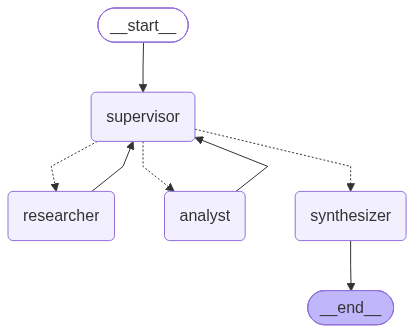

In [2]:
from graph import build_graph
graph = build_graph()
print(graph.get_graph().draw_mermaid())          # pegable en README / mermaid.live
try:
    from IPython.display import Image, display
    display(Image(graph.get_graph().draw_mermaid_png()))   # requiere internet (mermaid.ink)
except Exception as e:
    print("PNG no disponible:", e)

## 2. Ejecución con trazado de la delegación

In [3]:
from state import initial_state
from main import DEFAULT_QUERY

print("CONSULTA:", DEFAULT_QUERY, "\n")
final_state = None
for update in graph.stream(initial_state(DEFAULT_QUERY), config={"recursion_limit": 40}, stream_mode="updates"):
    for node, delta in update.items():
        print("=" * 70, "\n▶", node.upper())
        if node == "supervisor":
            print("  delega a  :", delta["next_agent"], f"(paso {delta['step_count']})")
            print("  instrucción:", delta["current_instruction"])
            print("  nota      :", delta["supervisor_notes"][-1])
        elif node in ("researcher", "analyst"):
            print(delta["contributions"][-1]["output"][:1000])
        else:
            print(delta["final_answer"])

CONSULTA: Investiga las reseñas de clientes de los auriculares AuraPods en la base de conocimiento, analiza el sentimiento de cada reseña y calcula el porcentaje de reseñas positivas y la calificación promedio. 



c:\Users\NORMA\Documents\aiengineer6\orquestador-multiagente\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3935: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


▶ SUPERVISOR
  delega a  : researcher (paso 1)
  instrucción: Busca en la base de conocimiento todas las reseñas de clientes disponibles para los auriculares AuraPods, incluyendo el texto de cada reseña, la calificación numérica otorgada y la fuente o identificador correspondiente.
  nota      : paso 1: researcher -> researcher | El pedido inicial requiere buscar las reseñas de los auriculares AuraPods. Como ningún especialista ha intervenido, el primer paso obligatorio es enviar al investigador a buscar los datos crudos en la base de conocimiento. | rúbrica: N/A


c:\Users\NORMA\Documents\aiengineer6\orquestador-multiagente\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3935: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
c:\Users\NORMA\Documents\aiengineer6\orquestador-multiagente\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3935: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


▶ RESEARCHER
A continuación se presentan todas las reseñas de clientes disponibles para los auriculares AuraPods encontradas en la base de conocimiento:

- **R1**: Calificación 5/5. Texto: "Excelente sonido, la batería dura todo el día. Totalmente recomendable." [fuente: doc-001]
- **R2**: Calificación 4/5. Texto: "Muy buena calidad de audio, aunque el estuche es un poco grande." [fuente: doc-001]
- **R3**: Calificación 2/5. Texto: "La conexión bluetooth es mala y se corta seguido. Decepcionante." [fuente: doc-001]
- **R4**: Calificación 5/5. Texto: "Cómodos y livianos, la cancelación de ruido es increíble." [fuente: doc-001]
- **R5**: Calificación 1/5. Texto: "Llegaron defectuosos, el auricular izquierdo no funciona. Pésimo servicio." [fuente: doc-001]
- **R6**: Calificación 4/5. Texto: "Buen producto por el precio, la batería es buena." [fuente: doc-001]
- **R7**: Calificación 3/5. Texto: "Sonido correcto, nada especial. El micrófono es regular." [fuente: doc-001]
- **R8**: Calificac

c:\Users\NORMA\Documents\aiengineer6\orquestador-multiagente\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3935: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


... (3 outputs left out)

c:\Users\NORMA\Documents\aiengineer6\orquestador-multiagente\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3935: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


▶ SUPERVISOR
  delega a  : synthesizer (paso 3)
  instrucción: Redacta el informe final respondiendo al usuario con el análisis de sentimiento de las 10 reseñas de los auriculares AuraPods, el porcentaje de reseñas positivas (60%) y la calificación promedio (3.5/5), incluyendo las fuentes correspondientes.
  nota      : paso 3: synthesizer -> synthesizer | El investigador recopiló 10 reseñas con fuente [doc-001] y el analista completó el análisis de sentimiento para cada una, calculó el promedio (3.5) y el porcentaje de reseñas positivas (60.0%) basándose estrictamente en los datos. Se cumplen todos los puntos de la rúbrica (Cobertura, Evidencia, Cálculo, Consistencia y Suficiencia). Procedemos a la síntesis. | rúbrica: 1. COBERTURA: Cumplida (reseñas, sentimiento, porcentaje de positivas y calificación promedio). 2. EVIDENCIA: Cumplida (datos con fuente [doc-001]). 3. CÁLCULO: Cumplida (cálculos derivados de las 10 reseñas reales). 4. CONSISTENCIA: Cumplida (coinciden las 10 reseñas, 

c:\Users\NORMA\Documents\aiengineer6\orquestador-multiagente\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3935: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


▶ SYNTHESIZER
A continuación se presenta el análisis completo de las reseñas de los clientes para los auriculares AuraPods, basado estrictamente en la investigación y los datos provistos.

### 1. Respuesta Directa y Análisis de Sentimiento
Se analizaron un total de 10 reseñas de clientes. El porcentaje de reseñas positivas es del **60.0%** y la calificación promedio es de **3.5 sobre 5**.

A continuación, el detalle del sentimiento por cada reseña:
- **R1** (Calificación 5/5): "Excelente sonido, la batería dura todo el día. Totalmente recomendable." $\rightarrow$ **Positivo** [fuente: doc-001]
- **R2** (Calificación 4/5): "Muy buena calidad de audio, aunque el estuche es un poco grande." $\rightarrow$ **Positivo** [fuente: doc-001]
- **R3** (Calificación 2/5): "La conexión bluetooth es mala y se corta seguido. Decepcionante." $\rightarrow$ **Negativo** [fuente: doc-001]
- **R4** (Calificación 5/5): "Cómodos y livianos, la cancelación de ruido es increíble." $\rightarrow$ **Positivo** [

## 3. Trazabilidad: ¿quién aportó qué?

In [4]:
result = graph.invoke(initial_state(DEFAULT_QUERY), config={"recursion_limit": 40})
for c in result["contributions"]:
    print(f"[paso {c['step']}] {c['agent']:<10} | {c['instruction'][:90]}")
print("\nPasos del supervisor:", result["step_count"], "| completada:", result["task_completed"])
print("\nNotas del supervisor:")
for n in result["supervisor_notes"]:
    print(" -", n)

c:\Users\NORMA\Documents\aiengineer6\orquestador-multiagente\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3935: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
c:\Users\NORMA\Documents\aiengineer6\orquestador-multiagente\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3935: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
c:\Users\NORMA\Documents\aiengineer6\orquestador-multiagente\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3935: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
c:\Users\NORMA\Documents\aiengineer6\orquestador-multiagente\.venv\Lib\site-packages\langchain_google_genai\c

[paso 1] researcher | Busca en la base de conocimiento todas las reseñas de clientes disponibles para los auricu
[paso 2] analyst    | Toma las 10 reseñas proporcionadas por el researcher, analiza el sentimiento individual de

Pasos del supervisor: 3 | completada: True

Notas del supervisor:
 - paso 1: researcher -> researcher | El pedido del usuario requiere investigar reseñas, analizar sentimiento y calcular estadísticas. Como es el inicio, debemos delegar la búsqueda de datos crudos al researcher. | rúbrica: N/A
 - paso 2: analyst -> analyst | El researcher ha completado la búsqueda de las 10 reseñas de AuraPods con sus fuentes. El siguiente paso lógico según el flujo es enviar estos datos al analyst para que procese el sentimiento, calcule el porcentaje de reseñas positivas y la calificación promedio. | rúbrica: 1. Cobertura: Parcial (falta análisis). 2. Evidencia: Cumple (10 reseñas con fuente). 3. Cálculo: N/A. 4. Consistencia: N/A. 5. Suficiencia: No.
 - paso 3: synthesizer -> s

## 4. (Opcional) Prueba del tope anti-bucle
Bajar `MAX_STEPS` fuerza el cierre anticipado y la síntesis informa la limitación:
`os.environ["MAX_STEPS"] = "2"` **antes** de importar `config` (reiniciar el kernel).